# Fraction-specific differential abundance

Test gene-level abundance differences between ASD and unaffected samples within
monosome and polysome fractions.


In [1]:
import os
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from scipy.stats import spearmanr

REFERENCE = 'Unaffected'
TEST = 'ASD'
ALPHA = 0.05
MIN_COUNT = 10
N_CPUS = min(4, os.cpu_count() or 1)
FRACTIONS = {
    'monosome': ('Monosome', 'mono'),
    'polysome': ('Polysome', 'poly'),
}

sns.set_theme(style = 'ticks', context = 'notebook')


In [2]:
# Locate the project and load the analysis metadata.


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / 'data').is_dir():
            return path
    raise FileNotFoundError('Could not find the project data directory.')


ROOT = find_root(Path.cwd().resolve())
DATA_DIR = ROOT / 'data'
RESULTS_DIR = ROOT / 'results'
RESULTS_DIR.mkdir(exist_ok = True)

metadata = pd.read_csv(DATA_DIR / 'metadata.tsv', sep = '\t', dtype = 'string')
metadata = metadata.set_index('sampleId')
metadata['condition'] = pd.Categorical(
    metadata['condition'],
    categories = [REFERENCE, TEST],
)
sample_ids = metadata.index.tolist()
min_samples = int(metadata['condition'].value_counts().min())


In [3]:
# Prepare each fraction's length-scaled Salmon counts.


def prepare_counts(folder: str, prefix: str):
    path = DATA_DIR / folder / 'salmon.merged.gene_counts_length_scaled.tsv'
    table = pd.read_csv(path, sep = '\t')
    columns = [f'{prefix}{sample_id}' for sample_id in sample_ids]
    missing = {'gene_id', 'gene_name', *columns}.difference(table.columns)

    if missing:
        raise ValueError(f'{path.name} is missing columns: {sorted(missing)}')
    if table['gene_id'].isna().any() or not table['gene_id'].is_unique:
        raise ValueError(f'Gene identifiers must be complete and unique in {folder}.')

    names = table.set_index('gene_id')['gene_name'].rename('geneName')
    counts = table.set_index('gene_id').loc[:, columns]
    counts.columns = sample_ids
    counts = np.rint(counts.T).astype('int64')
    counts.index.name = 'sampleId'
    counts.columns.name = 'geneId'

    keep = counts.ge(MIN_COUNT).sum(axis = 0).ge(min_samples)
    return counts.loc[:, keep], names


model_counts = {}
gene_names = {}
filter_records = []

for fraction, (folder, prefix) in FRACTIONS.items():
    model_counts[fraction], gene_names[fraction] = prepare_counts(folder, prefix)
    filter_records.append({
        'fraction': fraction,
        'totalGenes': len(gene_names[fraction]),
        'retainedGenes': model_counts[fraction].shape[1],
        'minimumCount': MIN_COUNT,
        'minimumSamples': min_samples,
    })

if not gene_names['monosome'].index.equals(gene_names['polysome'].index):
    raise ValueError('Monosome and polysome gene identifiers are not aligned.')
if not gene_names['monosome'].equals(gene_names['polysome']):
    raise ValueError('Monosome and polysome gene annotations are not aligned.')

filter_summary = pd.DataFrame(filter_records)
display(filter_summary)


,fraction,totalGenes,retainedGenes,minimumCount,minimumSamples
0,monosome,78941,21888,10,3
1,polysome,78941,21256,10,3


In [4]:
# Fit an independent DESeq2 model within each fraction.


def fit_model(counts: pd.DataFrame, names: pd.Series):
    dds = DeseqDataSet(
        counts = counts,
        metadata = metadata,
        design = '~condition',
        fit_type = 'parametric',
        size_factors_fit_type = 'ratio',
        refit_cooks = False,
        n_cpus = N_CPUS,
        quiet = True,
    )
    dds.deseq2()

    coefficient = 'condition[T.ASD]'
    if coefficient not in dds.varm['LFC'].columns:
        raise ValueError(f'Expected coefficient not found: {dds.varm["LFC"].columns}')

    statistics = DeseqStats(
        dds,
        contrast = ['condition', TEST, REFERENCE],
        alpha = ALPHA,
        cooks_filter = True,
        independent_filter = True,
        n_cpus = N_CPUS,
        quiet = True,
    )
    with redirect_stdout(StringIO()):
        statistics.summary()

    results = statistics.results_df.rename(columns = {
        'lfcSE': 'log2FoldChangeSE',
        'stat': 'statistic',
        'pvalue': 'pValue',
        'padj': 'adjustedPValue',
    }).copy()
    results.insert(0, 'geneName', names.reindex(results.index))
    results.index.name = 'geneId'
    results['significant'] = results['adjustedPValue'].lt(ALPHA)
    results = results.sort_values(
        ['adjustedPValue', 'pValue'],
        na_position = 'last',
    )
    return dds, results


models = {}
fraction_results = {}

for fraction in FRACTIONS:
    models[fraction], fraction_results[fraction] = fit_model(
        model_counts[fraction],
        gene_names[fraction],
    )


In [5]:
# Summarize convergence, outlier handling, and discoveries.

model_records = []
size_factor_tables = []

for fraction in FRACTIONS:
    dds = models[fraction]
    results = fraction_results[fraction]
    model_records.append({
        'fraction': fraction,
        'retainedGenes': len(results),
        'convergedGenes': int(dds.var['_LFC_converged'].fillna(False).sum()),
        'undefinedPValueGenes': int(results['pValue'].isna().sum()),
        'independentlyFilteredGenes': int(
            (results['pValue'].notna() & results['adjustedPValue'].isna()).sum()
        ),
        'significantGenes': int(results['significant'].sum()),
    })
    size_factors = dds.obs[['size_factors']].rename(
        columns = {'size_factors': 'sizeFactor'}
    )
    size_factors.insert(0, 'fraction', fraction)
    size_factor_tables.append(size_factors)

model_summary = pd.DataFrame(model_records)
size_factor_summary = pd.concat(size_factor_tables).reset_index()

display(model_summary)
display(size_factor_summary)

for fraction, results in fraction_results.items():
    print(f'{fraction.title()} leading results')
    display(results.head(10))


,fraction,retainedGenes,convergedGenes,undefinedPValueGenes,independentlyFilteredGenes,significantGenes
0,monosome,21888,21888,83,1697,192
1,polysome,21256,21256,93,2060,204


,sampleId,fraction,sizeFactor
0,07c06,monosome,0.947797
1,07c13,monosome,1.013942
2,07c16,monosome,1.106826
3,1851,monosome,1.148184
4,1861,monosome,0.851302
5,1916,monosome,1.000937
6,07c06,polysome,1.074161
7,07c13,polysome,0.919775
8,07c16,polysome,0.910695
9,1851,polysome,0.889553


Monosome leading results


,geneName,baseMean,log2FoldChange,log2FoldChangeSE,statistic,pValue,adjustedPValue,significant
geneId,,,,,,,,
ENSG00000240342.3,RPS2P5,20899.195841,-4.533400,0.288936,-15.689956,1.771770e-55,3.562676e-51,True
ENSG00000293650.1,ENSG00000293650,1112.068613,-9.705373,0.714115,-13.590769,4.542835e-42,4.567366e-38,True
ENSG00000245870.6,LINC00682,2651.934568,-3.929576,0.336417,-11.680660,1.600482e-31,1.072750e-27,True
ENSG00000230202.1,RPL29P4,3415.665360,-3.520065,0.330959,-10.635945,2.027637e-26,1.019293e-22,True
ENSG00000226686.11,LINC01535,142.291733,-5.027384,0.578874,-8.684772,3.795039e-18,1.526213e-14,True
ENSG00000237550.8,ENSG00000237550,7632.612819,-16.330136,1.970863,-8.285778,1.173395e-16,3.932439e-13,True
ENSG00000293320.1,ENSG00000293320,16561.890199,-2.616951,0.319225,-8.197834,2.447566e-16,7.030807e-13,True
ENSG00000168267.8,PTF1A,469.093133,-3.708161,0.460962,-8.044393,8.667396e-16,2.178550e-12,True
ENSG00000151615.3,POU4F2,1693.211678,-3.528319,0.446606,-7.900302,2.782290e-15,5.913795e-12,True


Polysome leading results


,geneName,baseMean,log2FoldChange,log2FoldChangeSE,statistic,pValue,adjustedPValue,significant
geneId,,,,,,,,
ENSG00000294153.1,ENSG00000294153,642.899516,7.738559,0.663956,11.655235,2.157853e-31,4.122146e-27,True
ENSG00000240342.3,RPS2P5,7981.651145,-4.102851,0.371820,-11.034502,2.604910e-28,2.488080e-24,True
ENSG00000285628.1,ENSG00000285628,227.987010,8.080272,0.835835,9.667303,4.151751e-22,2.643697e-18,True
ENSG00000109132.8,PHOX2B,4136.386249,-3.657136,0.383538,-9.535268,1.494989e-21,7.139692e-18,True
ENSG00000234665.10,LERFS,240.749523,4.017364,0.468209,8.580282,9.464097e-18,3.615853e-14,True
ENSG00000008196.14,TFAP2B,1885.433554,-3.184072,0.374162,-8.509866,1.741340e-17,5.544137e-14,True
ENSG00000151615.3,POU4F2,3890.207513,-3.764513,0.475343,-7.919566,2.383409e-15,6.504324e-12,True
ENSG00000237550.8,ENSG00000237550,3935.961725,-15.451221,1.967912,-7.851582,4.108214e-15,9.809902e-12,True
ENSG00000215845.13,TSTD1,184.146119,-5.985005,0.774429,-7.728279,1.090100e-14,2.259448e-11,True


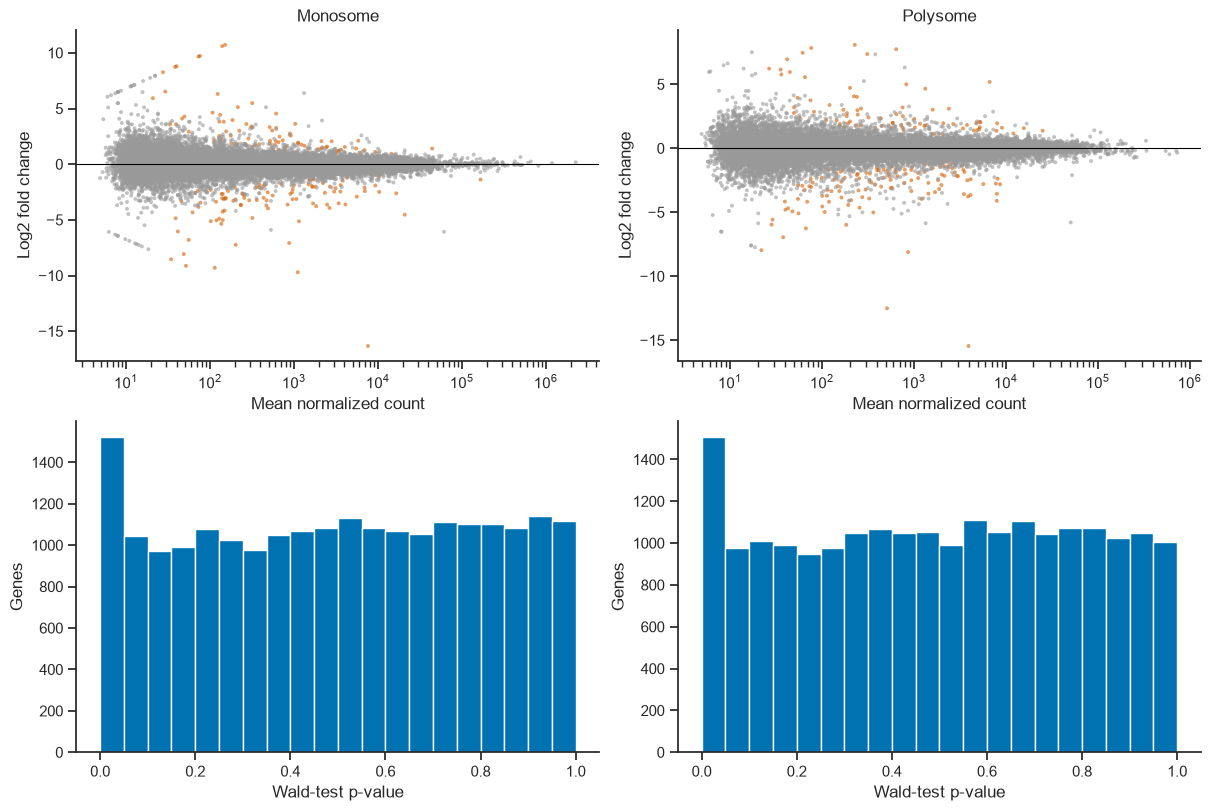

In [6]:
# Inspect effect sizes and unadjusted p-value distributions.

figure, axes = plt.subplots(2, 2, figsize = (12, 8), constrained_layout = True)

for column, (fraction, results) in enumerate(fraction_results.items()):
    colors = np.where(results['significant'], '#D55E00', '#999999')
    axes[0, column].scatter(
        results['baseMean'],
        results['log2FoldChange'],
        c = colors,
        s = 8,
        alpha = 0.6,
        linewidths = 0,
    )
    axes[0, column].axhline(0, color = 'black', linewidth = 0.8)
    axes[0, column].set(
        xscale = 'log',
        xlabel = 'Mean normalized count',
        ylabel = 'Log2 fold change',
        title = fraction.title(),
    )
    axes[1, column].hist(
        results['pValue'].dropna(),
        bins = np.linspace(0, 1, 21),
        color = '#0072B2',
        edgecolor = 'white',
    )
    axes[1, column].set(
        xlabel = 'Wald-test p-value',
        ylabel = 'Genes',
    )

sns.despine()
plt.show()


,xFraction,yFraction,genes,spearmanRho
0,input,monosome,20458,0.474129
1,input,polysome,20445,0.517005
2,monosome,polysome,20470,0.406608


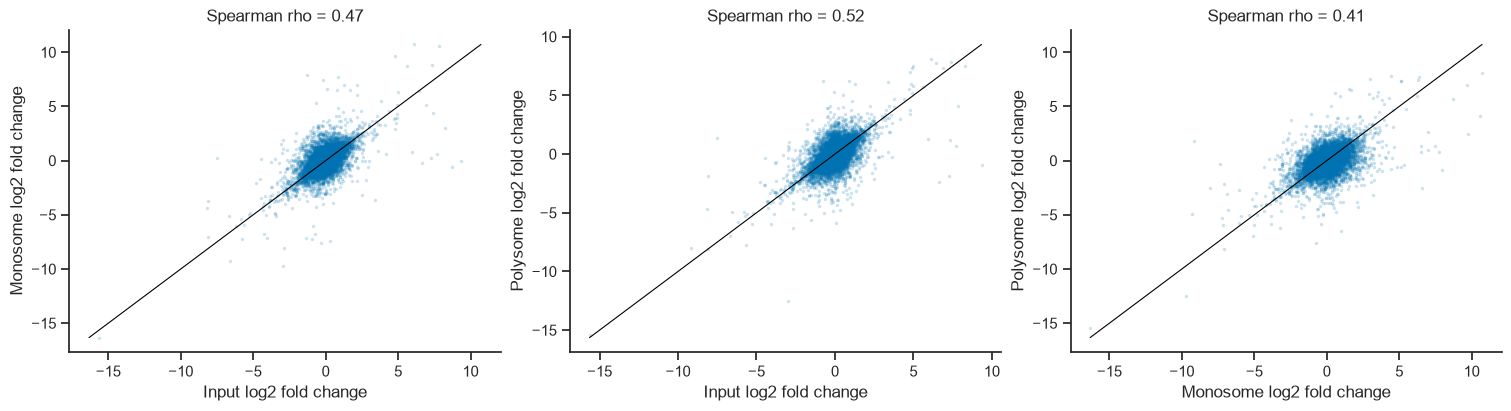

In [7]:
# Combine input and fraction-specific results for direct comparison.

input_results = pd.read_csv(
    RESULTS_DIR / 'inputDifferentialExpression.tsv',
    sep = '\t',
).set_index('geneId')
all_results = {'input': input_results, **fraction_results}
gene_index = pd.Index(
    sorted(set().union(*(results.index for results in all_results.values()))),
    name = 'geneId',
)
comparison = pd.DataFrame(index = gene_index)
comparison['geneName'] = gene_names['monosome'].reindex(gene_index)

metrics = [
    'log2FoldChange',
    'log2FoldChangeSE',
    'statistic',
    'pValue',
    'adjustedPValue',
    'significant',
]

for fraction, results in all_results.items():
    for metric in metrics:
        name = f'{fraction}{metric[0].upper()}{metric[1:]}'
        comparison[name] = results[metric].reindex(gene_index)

correlation_records = []
pairs = [
    ('input', 'monosome'),
    ('input', 'polysome'),
    ('monosome', 'polysome'),
]
figure, axes = plt.subplots(1, 3, figsize = (15, 4), constrained_layout = True)

for ax, (x_fraction, y_fraction) in zip(axes, pairs):
    x = comparison[f'{x_fraction}Log2FoldChange']
    y = comparison[f'{y_fraction}Log2FoldChange']
    complete = x.notna() & y.notna() & np.isfinite(x) & np.isfinite(y)
    rho = spearmanr(x[complete], y[complete]).statistic
    correlation_records.append({
        'xFraction': x_fraction,
        'yFraction': y_fraction,
        'genes': int(complete.sum()),
        'spearmanRho': rho,
    })
    limits = [
        min(x[complete].min(), y[complete].min()),
        max(x[complete].max(), y[complete].max()),
    ]
    ax.scatter(
        x[complete],
        y[complete],
        color = '#0072B2',
        s = 6,
        alpha = 0.2,
        linewidths = 0,
        rasterized = True,
    )
    ax.plot(limits, limits, color = 'black', linewidth = 0.8)
    ax.set(
        xlabel = f'{x_fraction.title()} log2 fold change',
        ylabel = f'{y_fraction.title()} log2 fold change',
        title = f'Spearman rho = {rho:.2f}',
    )

correlation_summary = pd.DataFrame(correlation_records)
display(correlation_summary)
sns.despine()
plt.show()


,signature,genes
0,Input,143
1,Input + Monosome + Polysome,84
2,Monosome,66
3,Polysome,64
4,Input + Polysome,46
5,Input + Monosome,32
6,Monosome + Polysome,10


,xFraction,yFraction,jointSignificantGenes,directionConcordantGenes
0,input,monosome,116,116
1,input,polysome,130,130
2,monosome,polysome,94,94


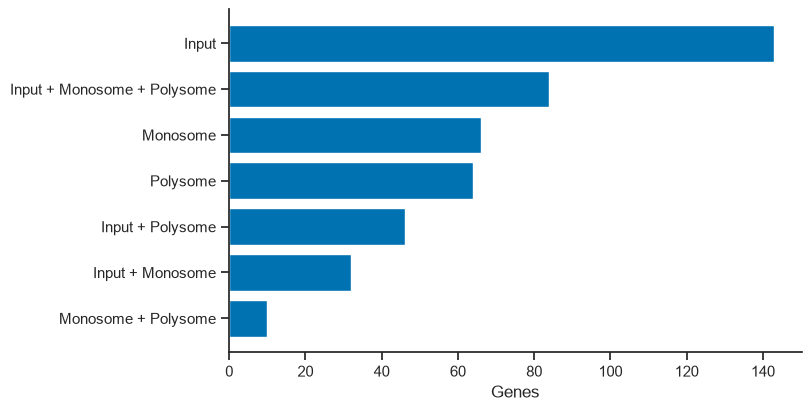

In [8]:
# Summarize overlap among significant gene sets.

significant = comparison[[
    'inputSignificant',
    'monosomeSignificant',
    'polysomeSignificant',
]].fillna(False).astype(bool)
significant = significant.loc[significant.any(axis = 1)]
patterns = significant.value_counts().reset_index(name = 'genes')


def format_pattern(row: pd.Series) -> str:
    labels = [
        fraction.title()
        for fraction in ('input', 'monosome', 'polysome')
        if row[f'{fraction}Significant']
    ]
    return ' + '.join(labels)


patterns['signature'] = patterns.apply(format_pattern, axis = 1)
patterns = patterns.sort_values('genes', ascending = False)
display(patterns[['signature', 'genes']])

direction_records = []

for x_fraction, y_fraction in pairs:
    joint = (
        significant[f'{x_fraction}Significant']
        & significant[f'{y_fraction}Significant']
    )
    joint_ids = joint.index[joint]
    x = comparison.loc[joint_ids, f'{x_fraction}Log2FoldChange']
    y = comparison.loc[joint_ids, f'{y_fraction}Log2FoldChange']
    concordant = np.sign(x) == np.sign(y)
    direction_records.append({
        'xFraction': x_fraction,
        'yFraction': y_fraction,
        'jointSignificantGenes': int(joint.sum()),
        'directionConcordantGenes': int(concordant.sum()),
    })

direction_summary = pd.DataFrame(direction_records)
display(direction_summary)

figure, ax = plt.subplots(figsize = (8, 4), constrained_layout = True)
ax.barh(patterns['signature'], patterns['genes'], color = '#0072B2')
ax.invert_yaxis()
ax.set(xlabel = 'Genes', ylabel = '')
sns.despine()
plt.show()


In [9]:
# Save complete model outputs and the cross-fraction comparison table.

for fraction, results in fraction_results.items():
    name = f'{fraction}DifferentialAbundance.tsv'
    results.reset_index().to_csv(RESULTS_DIR / name, sep = '\t', index = False)

comparison.reset_index().to_csv(
    RESULTS_DIR / 'fractionAbundanceComparison.tsv',
    sep = '\t',
    index = False,
)
correlation_summary.to_csv(
    RESULTS_DIR / 'fractionCorrelation.tsv',
    sep = '\t',
    index = False,
)
patterns[['signature', 'genes']].to_csv(
    RESULTS_DIR / 'fractionFdrOverlap.tsv',
    sep = '\t',
    index = False,
)
direction_summary.to_csv(
    RESULTS_DIR / 'fractionDirectionSummary.tsv',
    sep = '\t',
    index = False,
)
